In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost shap


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv('/content/online_gaming_behavior_dataset.csv')

print("Dataset uploaded successfully!")


Saving online_gaming_behavior_dataset.csv to online_gaming_behavior_dataset (1).csv
Dataset uploaded successfully!


In [4]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types and non-null values:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)


Number of rows and columns: (40034, 13)

Column names:
['PlayerID', 'Age', 'Gender', 'Location', 'GameGenre', 'PlayTimeHours', 'InGamePurchases', 'GameDifficulty', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked', 'EngagementLevel']

First five rows:


,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium



Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40034 entries, 0 to 40033
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PlayerID                   40034 non-null  int64  
 1   Age                        40034 non-null  int64  
 2   Gender                     40034 non-null  object 
 3   Location                   40034 non-null  object 
 4   GameGenre                  40034 non-null  object 
 5   PlayTimeHours              40034 non-null  float64
 6   InGamePurchases            40034 non-null  int64  
 7   GameDifficulty             40034 non-null  object 
 8   SessionsPerWeek            40034 non-null  int64  
 9   AvgSessionDurationMinutes  40034 non-null  int64  
 10  PlayerLevel                40034 non-null  int64  
 11  AchievementsUnlocked       40034 non-null  int64  
 12  EngagementLevel            40034 non-null  object 
dtypes: float64(1)

,Missing Values
PlayerID,0
Age,0
Gender,0
Location,0
GameGenre,0
PlayTimeHours,0
InGamePurchases,0
GameDifficulty,0
SessionsPerWeek,0
AvgSessionDurationMinutes,0



Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PlayerID,40034.0,NaN,NaN,NaN,29016.5,11556.964675,9000.0,19008.25,29016.5,39024.75,49033.0
Age,40034.0,NaN,NaN,NaN,31.992531,10.043227,15.0,23.0,32.0,41.0,49.0
Gender,40034,2,Male,23959,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,40034,4,USA,16000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GameGenre,40034,5,Sports,8048,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PlayTimeHours,40034.0,NaN,NaN,NaN,12.024365,6.914638,0.000115,6.067501,12.008002,17.963831,23.999592
InGamePurchases,40034.0,NaN,NaN,NaN,0.200854,0.400644,0.0,0.0,0.0,0.0,1.0
GameDifficulty,40034,3,Easy,20015,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SessionsPerWeek,40034.0,NaN,NaN,NaN,9.471774,5.763667,0.0,4.0,9.0,14.0,19.0
AvgSessionDurationMinutes,40034.0,NaN,NaN,NaN,94.792252,49.011375,10.0,52.0,95.0,137.0,179.0


In [5]:
df = df.copy()
df = df.drop_duplicates().reset_index(drop=True)
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

print("Dataset shape after removing duplicates:", df.shape)
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))


Dataset shape after removing duplicates: (40034, 13)

Missing values:


,Missing Values
PlayerID,0
Age,0
Gender,0
Location,0
GameGenre,0
PlayTimeHours,0
InGamePurchases,0
GameDifficulty,0
SessionsPerWeek,0
AvgSessionDurationMinutes,0


Numeric columns: ['PlayerID', 'Age', 'PlayTimeHours', 'InGamePurchases', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked']


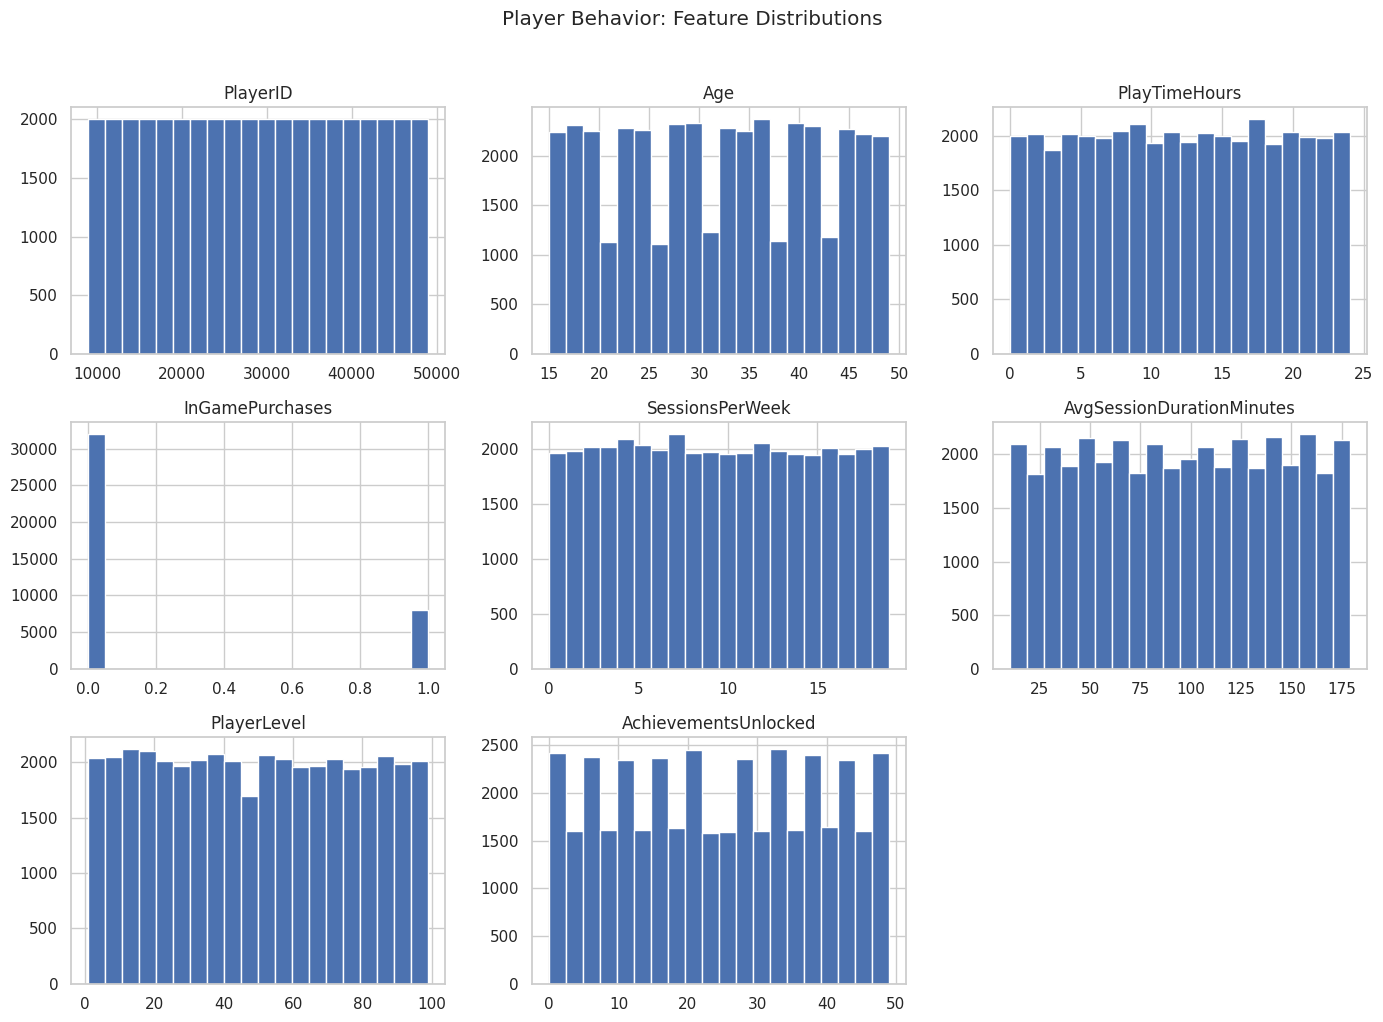

In [6]:
numeric_df = df.select_dtypes(include=np.number)

print("Numeric columns:", numeric_df.columns.tolist())

if numeric_df.shape[1] > 0:
    numeric_df.hist(figsize=(14, 10), bins=20)
    plt.suptitle("Player Behavior: Feature Distributions", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns found.")


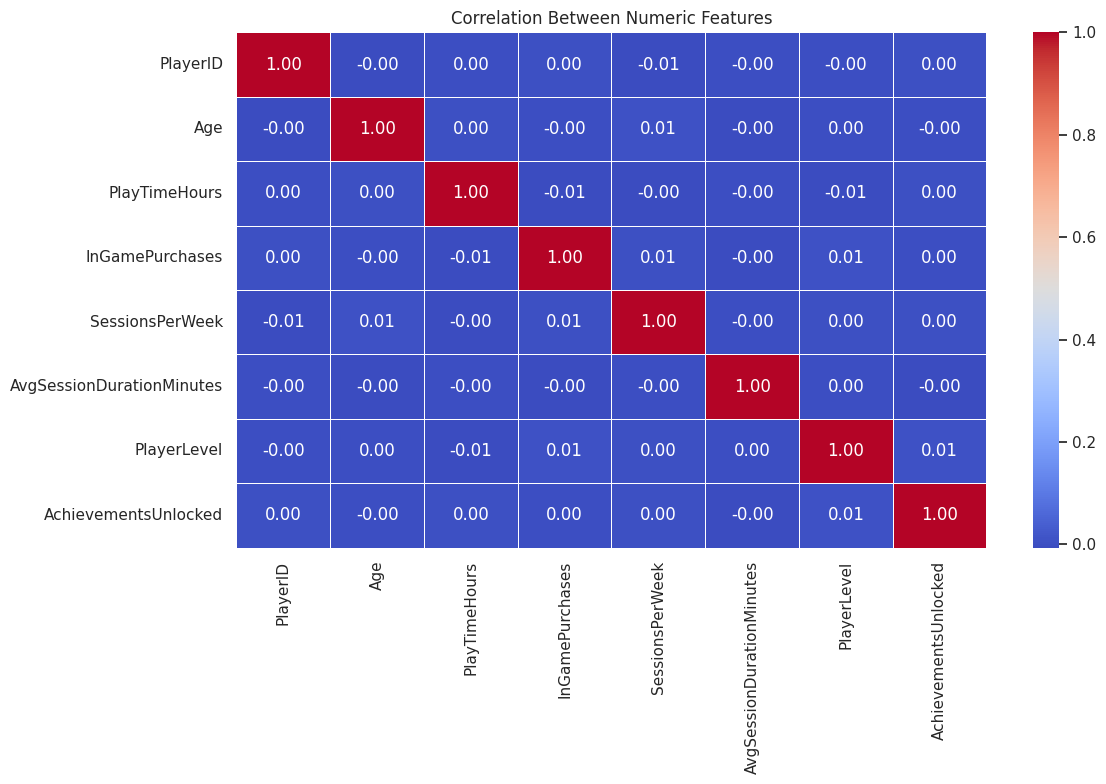

In [7]:
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(12, 8))

    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Correlation Between Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numeric columns are needed for a correlation heatmap.")


In [8]:
print("All columns:")
for col in df.columns:
    print("-", repr(col))

print("\nPossible churn or engagement targets:")

for col in df.columns:
    if any(word in col.lower() for word in
           ["churn", "engagement", "retention", "inactive", "target", "label"]):
        print(f"\nColumn: {col}")
        print(df[col].value_counts(dropna=False).head(20))


All columns:
- 'PlayerID'
- 'Age'
- 'Gender'
- 'Location'
- 'GameGenre'
- 'PlayTimeHours'
- 'InGamePurchases'
- 'GameDifficulty'
- 'SessionsPerWeek'
- 'AvgSessionDurationMinutes'
- 'PlayerLevel'
- 'AchievementsUnlocked'
- 'EngagementLevel'

Possible churn or engagement targets:

Column: EngagementLevel
EngagementLevel
Medium    19374
High      10336
Low       10324
Name: count, dtype: int64


In [9]:
df.to_csv("cleaned_player_behavior.csv", index=False)

print("Cleaned dataset saved successfully.")

files.download("cleaned_player_behavior.csv")


Cleaned dataset saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Engagement distribution:


,Player Count
EngagementLevel,
Medium,19374
High,10336
Low,10324



Engagement percentages:


,Percentage
EngagementLevel,
Medium,48.39
High,25.82
Low,25.79


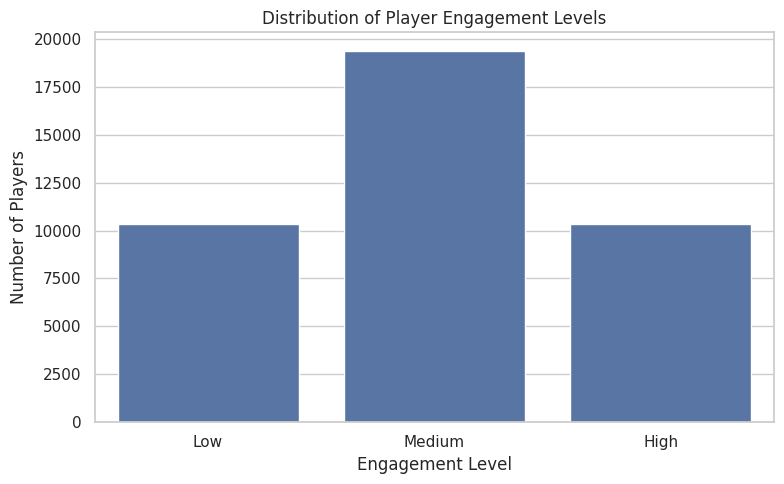

In [10]:
print("Engagement distribution:")
display(df["EngagementLevel"].value_counts().to_frame("Player Count"))

print("\nEngagement percentages:")
display(
    (df["EngagementLevel"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="EngagementLevel",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Player Engagement Levels")
plt.xlabel("Engagement Level")
plt.ylabel("Number of Players")
plt.tight_layout()
plt.show()


In [11]:
features = [
    "PlayTimeHours",
    "InGamePurchases",
    "SessionsPerWeek",
    "AvgSessionDurationMinutes",
    "PlayerLevel",
    "AchievementsUnlocked"
]

engagement_summary = (
    df.groupby("EngagementLevel")[features]
    .mean()
    .round(2)
)

display(engagement_summary)


,PlayTimeHours,InGamePurchases,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked
EngagementLevel,,,,,,
High,12.07,0.21,14.25,131.92,50.82,25.10
Low,12.10,0.20,4.53,66.88,46.10,22.66
Medium,11.96,0.20,9.55,89.86,50.93,25.22


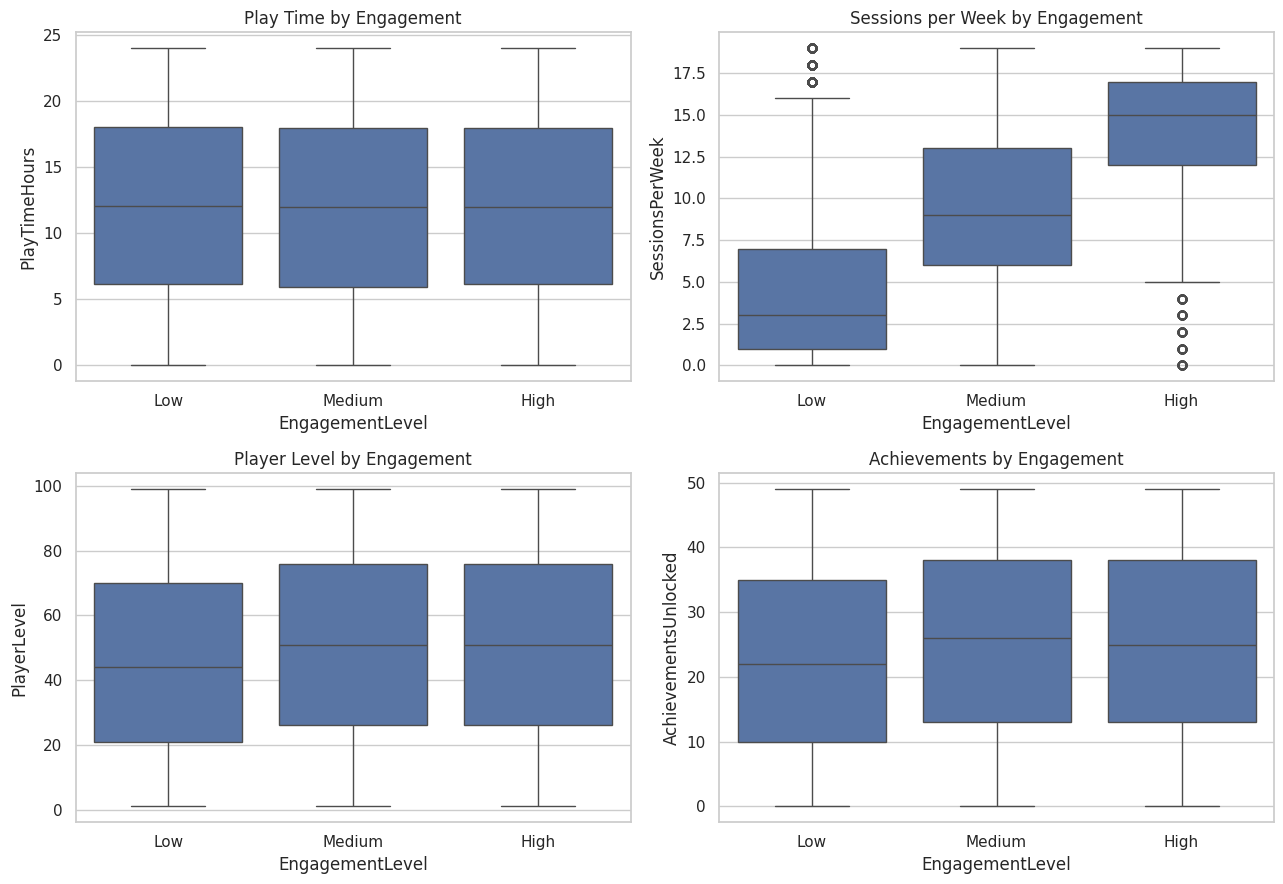

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.boxplot(
    data=df, x="EngagementLevel", y="PlayTimeHours",
    order=["Low", "Medium", "High"], ax=axes[0, 0]
)
axes[0, 0].set_title("Play Time by Engagement")

sns.boxplot(
    data=df, x="EngagementLevel", y="SessionsPerWeek",
    order=["Low", "Medium", "High"], ax=axes[0, 1]
)
axes[0, 1].set_title("Sessions per Week by Engagement")

sns.boxplot(
    data=df, x="EngagementLevel", y="PlayerLevel",
    order=["Low", "Medium", "High"], ax=axes[1, 0]
)
axes[1, 0].set_title("Player Level by Engagement")

sns.boxplot(
    data=df, x="EngagementLevel", y="AchievementsUnlocked",
    order=["Low", "Medium", "High"], ax=axes[1, 1]
)
axes[1, 1].set_title("Achievements by Engagement")

plt.tight_layout()
plt.show()


In [13]:
target = "EngagementLevel"

X = df.drop(columns=[target, "PlayerID"])
y = df[target]

print("Feature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.value_counts())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)


Feature columns:
['Age', 'Gender', 'Location', 'GameGenre', 'PlayTimeHours', 'InGamePurchases', 'GameDifficulty', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked']

Target classes:
EngagementLevel
Medium    19374
High      10336
Low       10324
Name: count, dtype: int64

Feature shape: (40034, 11)
Target shape: (40034,)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 32027
Testing rows: 8007


In [16]:
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from xgboost import XGBClassifier

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Class mapping:")
for number, name in enumerate(label_encoder.classes_):
    print(f"{name} = {number}")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=42,
        eval_metric="mlogloss",
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1 Score (macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

    trained_models[name] = pipeline

print("\nAll models trained successfully!")


Class mapping:
High = 0
Low = 1
Medium = 2

Training Logistic Regression...

Training Random Forest...

Training XGBoost...

All models trained successfully!


In [17]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score (macro)",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision (macro),Recall (macro),F1 Score (macro)
0,XGBoost,0.9125,0.9130,0.9029,0.9076
1,Random Forest,0.8948,0.9006,0.8805,0.8894
2,Logistic Regression,0.8184,0.8258,0.8005,0.8111


Best model: XGBoost
              precision    recall  f1-score   support

        High       0.92      0.88      0.90      2067
         Low       0.91      0.89      0.90      2065
      Medium       0.91      0.95      0.93      3875

    accuracy                           0.91      8007
   macro avg       0.91      0.90      0.91      8007
weighted avg       0.91      0.91      0.91      8007



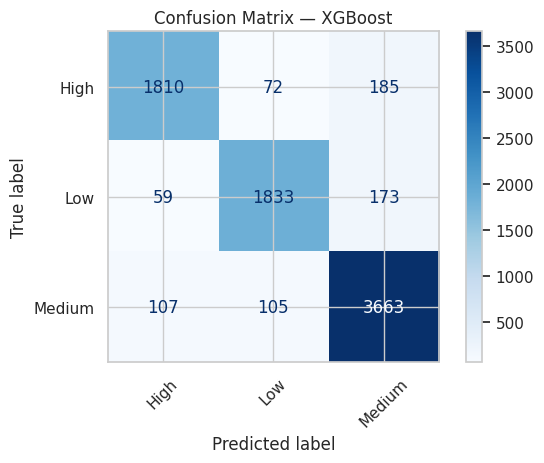

In [18]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Best model:", best_model_name)

print(classification_report(
    y_test,
    best_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    cmap="Blues",
    xticks_rotation=45
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


,Feature,Importance
3,num__SessionsPerWeek,0.354811
4,num__AvgSessionDurationMinutes,0.258119
6,num__AchievementsUnlocked,0.036188
5,num__PlayerLevel,0.033953
1,num__PlayTimeHours,0.020211
0,num__Age,0.019405
16,cat__GameGenre_Sports,0.019336
7,cat__Gender_Female,0.019325
14,cat__GameGenre_RPG,0.019221
13,cat__GameGenre_Action,0.019106


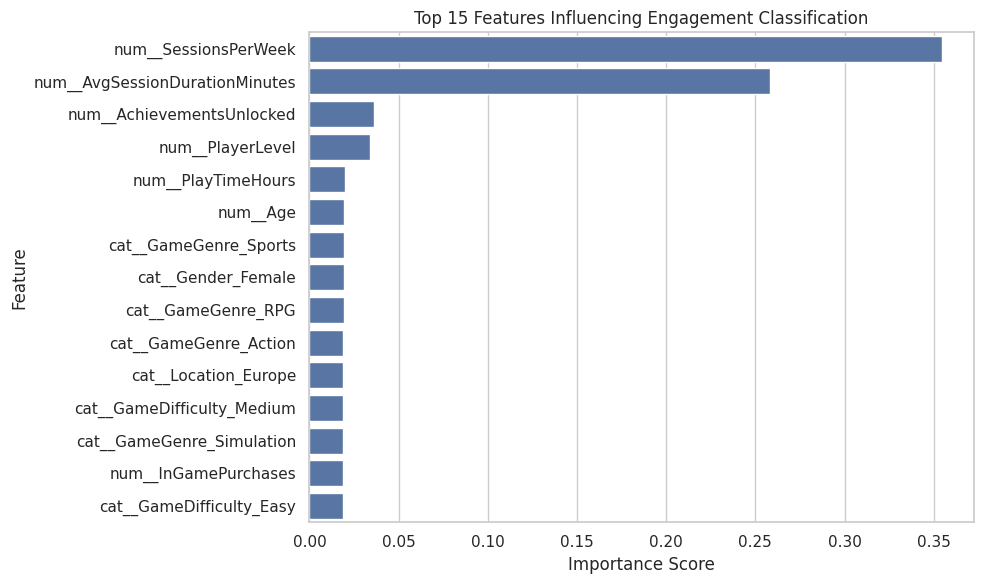

In [19]:
best_model = trained_models["XGBoost"]
preprocessor_fitted = best_model.named_steps["preprocessor"]
xgb_model = best_model.named_steps["model"]
feature_names = preprocessor_fitted.get_feature_names_out()
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Engagement Classification")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


,Feature,Importance
3,num__SessionsPerWeek,0.354811
4,num__AvgSessionDurationMinutes,0.258119
6,num__AchievementsUnlocked,0.036188
5,num__PlayerLevel,0.033953
1,num__PlayTimeHours,0.020211
0,num__Age,0.019405
16,cat__GameGenre_Sports,0.019336
7,cat__Gender_Female,0.019325
14,cat__GameGenre_RPG,0.019221
13,cat__GameGenre_Action,0.019106


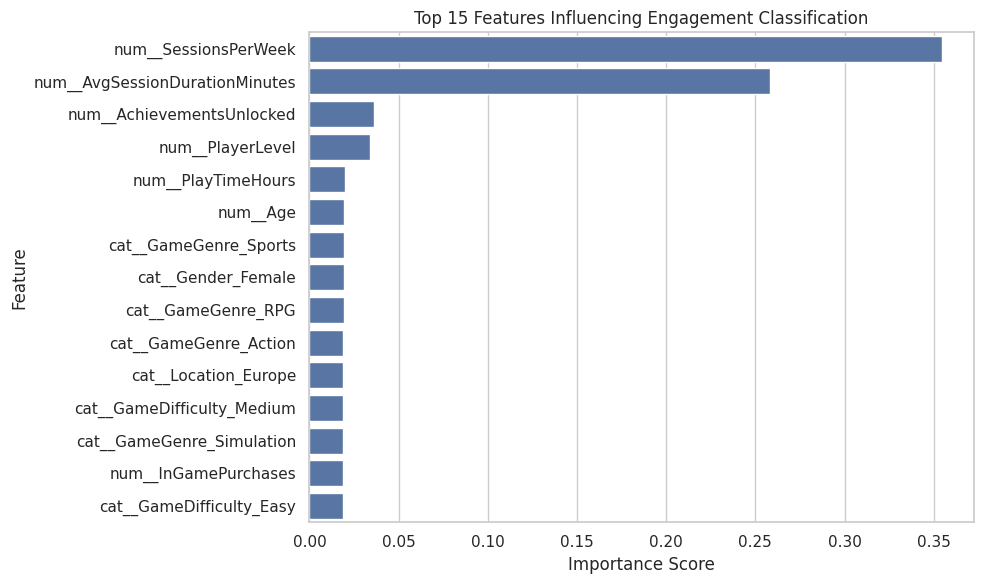

In [20]:
best_model = trained_models["XGBoost"]
preprocessor_fitted = best_model.named_steps["preprocessor"]
xgb_model = best_model.named_steps["model"]
feature_names = preprocessor_fitted.get_feature_names_out()
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
).head(15)

display(importance_df)
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Top 15 Features Influencing Engagement Classification")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [21]:
display(importance_df)
print("Dataset columns:")
print(df.columns.tolist())

print("\nEngagementLevel distribution:")
print(df["EngagementLevel"].value_counts())

print("\nUnique engagement levels:")
print(df["EngagementLevel"].unique())


,Feature,Importance
3,num__SessionsPerWeek,0.354811
4,num__AvgSessionDurationMinutes,0.258119
6,num__AchievementsUnlocked,0.036188
5,num__PlayerLevel,0.033953
1,num__PlayTimeHours,0.020211
0,num__Age,0.019405
16,cat__GameGenre_Sports,0.019336
7,cat__Gender_Female,0.019325
14,cat__GameGenre_RPG,0.019221
13,cat__GameGenre_Action,0.019106


Dataset columns:
['PlayerID', 'Age', 'Gender', 'Location', 'GameGenre', 'PlayTimeHours', 'InGamePurchases', 'GameDifficulty', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked', 'EngagementLevel']

EngagementLevel distribution:
EngagementLevel
Medium    19374
High      10336
Low       10324
Name: count, dtype: int64

Unique engagement levels:
['Medium' 'High' 'Low']


SessionsPerWeek        AvgSessionDurationMinutes         \
                           mean median                      mean median   
EngagementLevel                                                           
High                      14.25   15.0                    131.92  137.0   
Low                        4.53    3.0                     66.88   53.0   
Medium                     9.55    9.0                     89.86   84.0   

                PlayTimeHours        PlayerLevel        AchievementsUnlocked  \
                         mean median        mean median                 mean   
EngagementLevel                                                                
High                    12.07  11.98       50.82   51.0                25.10   
Low                     12.10  12.07       46.10   44.0                22.66   
Medium                  11.96  11.99       50.93   51.0                25.22   

                        
                median  
EngagementLevel         
High              25.0  
Low               22.0  
Medium            26.0

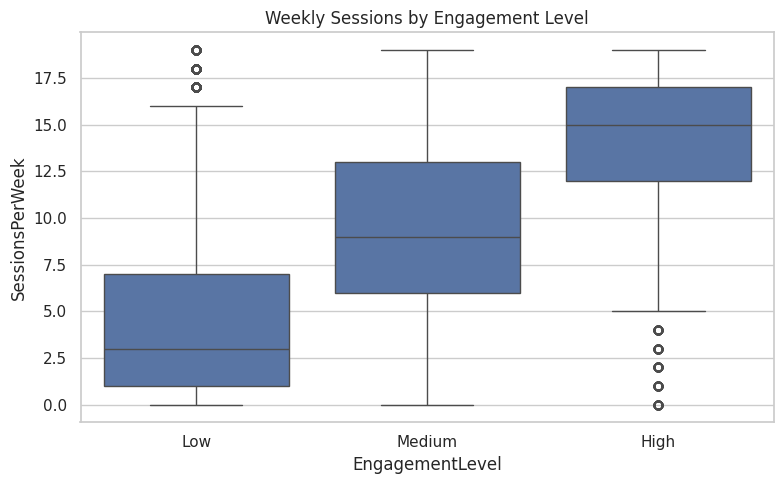

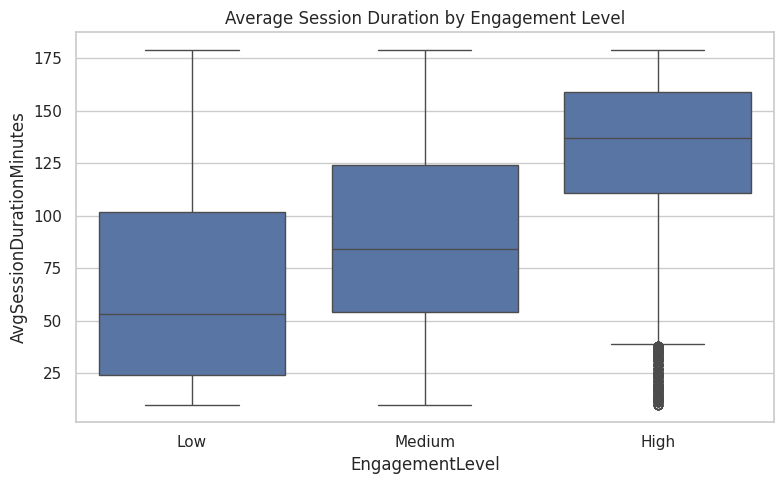

In [22]:
behavior_summary = (
    df.groupby("EngagementLevel")[
        [
            "SessionsPerWeek",
            "AvgSessionDurationMinutes",
            "PlayTimeHours",
            "PlayerLevel",
            "AchievementsUnlocked"
        ]
    ]
    .agg(["mean", "median"])
    .round(2)
)

display(behavior_summary)
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="EngagementLevel",
    y="SessionsPerWeek",
    order=["Low", "Medium", "High"]
)
plt.title("Weekly Sessions by Engagement Level")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="EngagementLevel",
    y="AvgSessionDurationMinutes",
    order=["Low", "Medium", "High"]
)
plt.title("Average Session Duration by Engagement Level")
plt.tight_layout()
plt.show()


In [23]:
print("Sessions per week by engagement level:")
display(
    df.groupby("EngagementLevel")["SessionsPerWeek"]
    .describe()
    .round(2)
)

print("\nAverage session duration by engagement level:")
display(
    df.groupby("EngagementLevel")["AvgSessionDurationMinutes"]
    .describe()
    .round(2)
)

from sklearn.base import clone
from sklearn.metrics import accuracy_score, classification_report

behavior_features = [
    "SessionsPerWeek",
    "AvgSessionDurationMinutes"
]

X_behavior = df[behavior_features]
y_behavior = y_encoded

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_behavior,
    y_behavior,
    test_size=0.20,
    random_state=42,
    stratify=y_behavior
)

behavior_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1
)

behavior_model.fit(Xb_train, yb_train)
behavior_predictions = behavior_model.predict(Xb_test)

print(
    "\nAccuracy using only session frequency and duration:",
    round(accuracy_score(yb_test, behavior_predictions), 4)
)


Sessions per week by engagement level:


,count,mean,std,min,25%,50%,75%,max
EngagementLevel,,,,,,,,
High,10336.0,14.25,3.91,0.0,12.0,15.0,17.0,19.0
Low,10324.0,4.53,4.86,0.0,1.0,3.0,7.0,19.0
Medium,19374.0,9.55,4.76,0.0,6.0,9.0,13.0,19.0



Average session duration by engagement level:


,count,mean,std,min,25%,50%,75%,max
EngagementLevel,,,,,,,,
High,10336.0,131.92,34.07,10.0,111.0,137.0,159.0,179.0
Low,10324.0,66.88,48.59,10.0,24.0,53.0,102.0,179.0
Medium,19374.0,89.86,43.72,10.0,54.0,84.0,124.0,179.0



Accuracy using only session frequency and duration: 0.8541


In [24]:
print("Mean behavior by engagement level:")
display(
    df.groupby("EngagementLevel")[
        ["SessionsPerWeek", "AvgSessionDurationMinutes"]
    ].mean().round(2)
)


df["SessionsPerWeek_Bin"] = pd.cut(
    df["SessionsPerWeek"],
    bins=[-1, 4, 9, 14, 19],
    labels=["0-4", "5-9", "10-14", "15-19"]
)

print("\nEngagement distribution by weekly sessions:")
display(
    pd.crosstab(
        df["SessionsPerWeek_Bin"],
        df["EngagementLevel"],
        normalize="index"
    ).round(3)
)


df.drop(columns=["SessionsPerWeek_Bin"], inplace=True)


Mean behavior by engagement level:


,SessionsPerWeek,AvgSessionDurationMinutes
EngagementLevel,,
High,14.25,131.92
Low,4.53,66.88
Medium,9.55,89.86



Engagement distribution by weekly sessions:


EngagementLevel,High,Low,Medium
SessionsPerWeek_Bin,,,
0-4,0.034,0.659,0.307
5-9,0.068,0.196,0.736
10-14,0.377,0.106,0.517
15-19,0.560,0.066,0.374


In [25]:

%pip install -q shap

import shap
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)
print("Ready to explain the XGBoost model.")


SHAP version: 0.52.0
Ready to explain the XGBoost model.


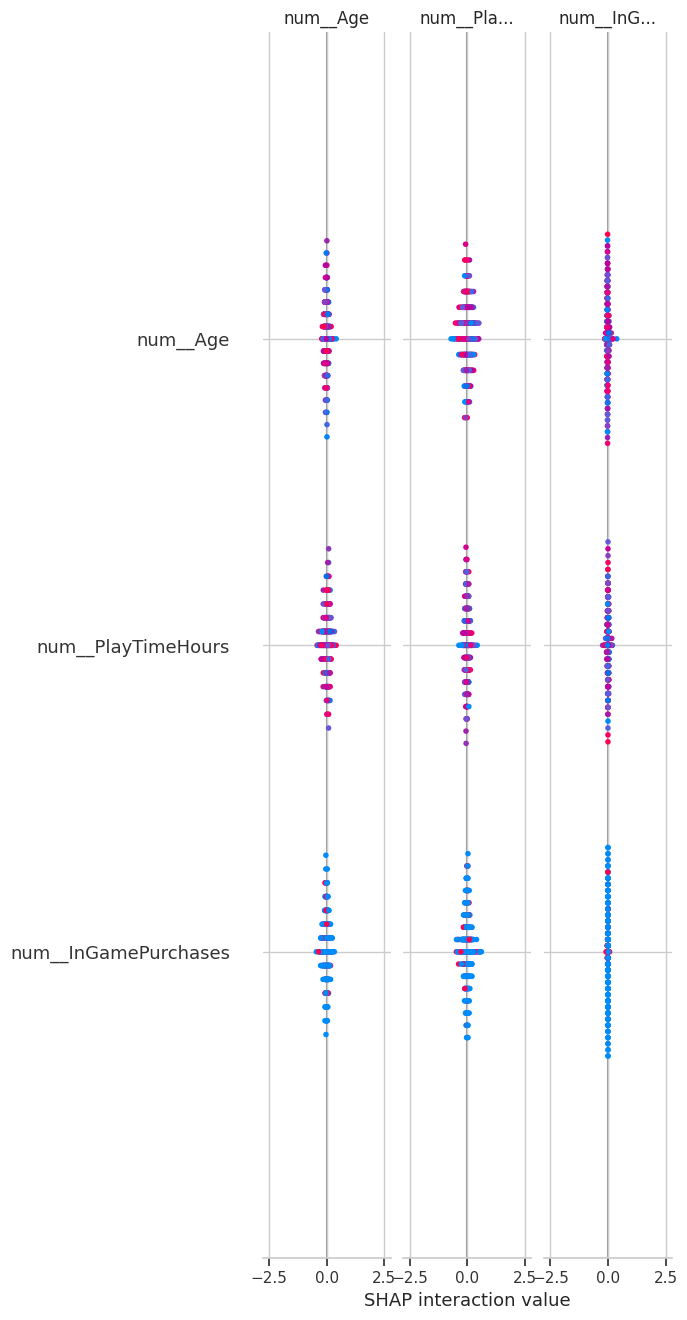

In [26]:
X_sample = X_test[:300]

X_sample_transformed = (
    best_model.named_steps["preprocessor"]
    .transform(X_sample)
)


explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_sample_transformed)


shap.summary_plot(
    shap_values,
    X_sample_transformed,
    feature_names=feature_names,
    max_display=15
)


In [27]:
results_df.to_csv("model_performance.csv", index=False)


importance_df.to_csv("feature_importance.csv", index=False)


df.to_csv("player_engagement_data.csv", index=False)

print("Files exported successfully:")
print("1. model_performance.csv")
print("2. feature_importance.csv")
print("3. player_engagement_data.csv")


Files exported successfully:
1. model_performance.csv
2. feature_importance.csv
3. player_engagement_data.csv
